# Diagnostics: residuals, calibration, feature importance

Three standard diagnostics that no notebook in `01`-`08` or `10` currently
produces, built here from materialized artifacts under `reports/` rather than
by re-fitting anything (per `readme.md`, a frozen run is not edited to improve
a reported score):

1. ACF/PACF and Ljung-Box test on SARIMAX test-phase residuals.
2. A reliability/calibration diagram for a quantile forecast, overall and for
   cold-evening hours.
3. A feature-importance plot for a saved tabular pipeline.

This notebook only reads existing files under `reports/`; it does not call
`scripts/execute_research_notebooks.py`, `scripts/run_rte_risk_experiment.py`,
or any other build/execute script, and does not edit notebooks `01`-`08` or
`10`.

In [1]:
import sys
import warnings
from pathlib import Path

import gzip
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path("..").resolve()))
from scripts.evaluation import load_data

plt.rcParams.update({"figure.figsize": (11, 3.5), "axes.grid": True})

DATA_DIR = Path("../data")
REPORTS_DIR = Path("../reports")
TEST_START, TEST_END = "2025-07-01", "2026-06-30"


## Section 1 - SARIMAX residual diagnostics

Source: `reports/research_v2/20261020T164443776583Z/fits/sarimax__national__test__8fab0ab43157.json`
(monthly rolling re-fits, one per test-year origin) and the paired forecast file
`.../forecasts/sarimax__national__test__8fab0ab43157.csv.gz` - matched by the shared
hash suffix `8fab0ab43157` in the `fits/` and `forecasts/` directories. Nothing is
refit here; the SARIMAX model is already fit and its forecasts already written to disk.

In [2]:
RUN_DIR = REPORTS_DIR / "research_v2/20261020T164443776583Z"
sarimax_fit_path = RUN_DIR / "fits/sarimax__national__test__8fab0ab43157.json"
sarimax_forecast_path = RUN_DIR / "forecasts/sarimax__national__test__8fab0ab43157.csv.gz"

assert sarimax_fit_path.exists(), sarimax_fit_path
assert sarimax_forecast_path.exists(), sarimax_forecast_path

fit_episodes = json.loads(sarimax_fit_path.read_text())
orders = {tuple(ep["params"]["order"]) for ep in fit_episodes}
seasonal_orders = {tuple(ep["params"]["seasonal_order"]) for ep in fit_episodes}
converged = sum(1 for ep in fit_episodes if ep["metadata"]["converged"])

print(f"{len(fit_episodes)} rolling-refit episodes over the test year")
print(f"order={orders}, seasonal_order={seasonal_orders}")
print(f"converged in {converged}/{len(fit_episodes)} episodes "
      f"(non-converged runs still returned usable parameters; see fit metadata 'warnings')")


13 rolling-refit episodes over the test year
order={(1, 0, 0)}, seasonal_order={(1, 0, 0, 24)}
converged in 3/13 episodes (non-converged runs still returned usable parameters; see fit metadata 'warnings')


In [3]:
sarimax_fc = pd.read_csv(sarimax_forecast_path)
sarimax_fc["delivery_time"] = pd.to_datetime(sarimax_fc["delivery_time"], utc=True)
sarimax_fc = sarimax_fc.set_index("delivery_time").sort_index()
print(f"{len(sarimax_fc):,} forecast rows, model={sarimax_fc['model'].unique()}")
sarimax_fc[["prediction_mw"]].head(3)


8,760 forecast rows, model=<ArrowStringArray>
['sarimax__national']
Length: 1, dtype: str


,prediction_mw
delivery_time,
2025-06-30 22:00:00+00:00,51151.544701
2025-06-30 23:00:00+00:00,47325.548717
2025-07-01 00:00:00+00:00,45836.468537


In [4]:
elec = load_data(DATA_DIR)
test = elec.loc[TEST_START:TEST_END]
actual_utc = test["load_mw"].copy()
actual_utc.index = actual_utc.index.tz_convert("UTC")
print(f"{len(actual_utc):,} actual rows, {actual_utc.index.min()} to {actual_utc.index.max()}")

paired = pd.concat(
    [actual_utc.rename("actual_mw"), sarimax_fc["prediction_mw"]], axis=1
).dropna()
residual = paired["prediction_mw"] - paired["actual_mw"]
print(f"{len(residual):,} paired rows; residual (forecast - actual) "
      f"mean={residual.mean():.1f} MW, std={residual.std():.1f} MW")


8,759 actual rows, 2025-06-30 22:00:00+00:00 to 2026-06-30 21:00:00+00:00
8,759 paired rows; residual (forecast - actual) mean=-33.0 MW, std=4307.8 MW


C:\Users\jgree\AppData\Local\Temp\ipykernel_46924\1324342292.py:7: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  paired = pd.concat(


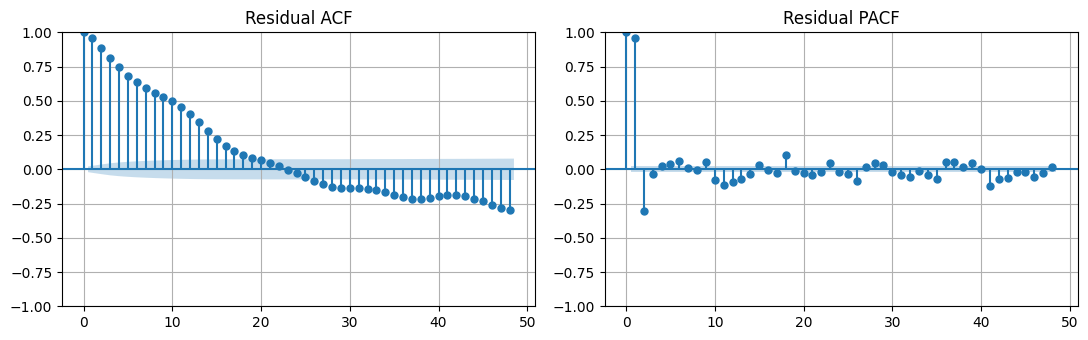

In [5]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
plot_acf(residual, lags=48, ax=axes[0])
axes[0].set_title("Residual ACF")
plot_pacf(residual, lags=48, ax=axes[1], method="ywm")
axes[1].set_title("Residual PACF")
plt.tight_layout()
plt.show()


In [6]:
from statsmodels.stats.diagnostic import acorr_ljungbox

lb = acorr_ljungbox(residual, lags=[24, 48], return_df=True)
lb


,lb_stat,lb_pvalue
24,49815.859240,0.0
48,57438.365521,0.0


A p-value below 0.05 at a given lag rejects the null of no residual autocorrelation
up to that lag; a p-value at or above 0.05 fails to reject it.

**Result:** `lb_pvalue = 0.0` at both lag 24 and lag 48 (`lb_stat` = 49,816 and
57,438). The null of no residual autocorrelation is rejected at both lags - the
SARIMAX(1,0,0)(1,0,0)[24] residuals are significantly autocorrelated, consistent
with the structure still visible in the ACF/PACF plots above. The residual mean
(-33 MW) is small relative to its std (4,308 MW), so the model is close to
unbiased on average but leaves autocorrelated structure unmodeled.

## Section 2 - reliability / calibration diagram

Diagnosing the actual recommended quantile model,
`lab__lightgbm_quantile__combined__stacked__w5__residual` (the paired uncertainty
model for the frozen point recommendation). Its native per-quantile forecasts
live under
`reports/rte_risk/20261020T213640021260Z/forecasts/lab__lightgbm_quantile__combined__stacked__w5__residual__native_quantile_test__*.csv.gz` -
8 files, each with one real, distinct `quantile_level` and a fully populated
`prediction_mw` column. This supersedes the previous version of this section,
which used `reports/forecasts/candidate_empirical_intervals_test.csv.gz`
(model `rte_correction_proxy`) on the mistaken premise that the files above only
carried a degenerate all-`NaN` `quantile_level` column - they don't. Nothing is
refit here; all 8 files are already-materialized forecasts.

In [7]:
RISK_RUN_DIR = REPORTS_DIR / "rte_risk/20261020T213640021260Z"
QUANTILE_MODEL = "lab__lightgbm_quantile__combined__stacked__w5__residual"

quantile_files = sorted((RISK_RUN_DIR / "forecasts").glob(
    f"{QUANTILE_MODEL}__native_quantile_test__*.csv.gz"))
print(f"{len(quantile_files)} native-quantile test forecast files")

quantile_frames = []
for path in quantile_files:
    f = pd.read_csv(path)
    levels = f["quantile_level"].dropna().unique()
    assert len(levels) == 1, f"{path.name}: expected one distinct quantile_level, got {levels}"
    assert f["prediction_mw"].notna().all(), f"{path.name}: has missing prediction_mw"
    f["delivery_time"] = pd.to_datetime(f["delivery_time"], utc=True)
    quantile_frames.append(f[["delivery_time", "quantile_level", "prediction_mw"]])

quantile_long = pd.concat(quantile_frames, ignore_index=True)
quantile_wide = (quantile_long
                  .pivot(index="delivery_time", columns="quantile_level", values="prediction_mw")
                  .sort_index())
LEVELS = sorted(quantile_wide.columns)
print(f"quantile levels present: {LEVELS}")
quantile_wide.head(3)


8 native-quantile test forecast files


quantile levels present: [0.05, 0.075, 0.25, 0.5, 0.75, 0.9, 0.95, 0.975]


quantile_level,0.050,0.075,0.250,0.500,0.750,0.900,0.950,0.975
delivery_time,,,,,,,,
2025-06-30 22:00:00+00:00,46409.885068,46358.165341,47233.001702,47448.131024,47764.641232,48185.247381,48343.278286,48531.249376
2025-06-30 23:00:00+00:00,42734.756277,42645.543686,43222.825210,43545.346211,43773.573069,44242.597164,44460.872600,44912.446146
2025-07-01 00:00:00+00:00,41319.004966,41260.461636,41901.433486,42168.178321,42383.243577,42759.645314,42978.870237,43364.804130


In [8]:
matched = pd.read_csv(REPORTS_DIR / "manager_report_20261021/diagnostics/matched_hourly.csv")
matched["delivery_time"] = pd.to_datetime(matched["delivery_time"], utc=True)
matched = matched.set_index("delivery_time").sort_index()

cal = quantile_wide.join(matched[["cold_evening", "temperature_c"]], how="inner")
cal = cal.join(actual_utc.rename("actual_mw"), how="inner")
print(f"{len(cal):,} rows joined; {int(cal['cold_evening'].sum())} cold-evening hours")

def empirical_coverage(frame):
    return {level: float((frame["actual_mw"] <= frame[level]).mean()) for level in LEVELS}

overall_cov = empirical_coverage(cal)
cold_cov = empirical_coverage(cal[cal["cold_evening"].astype(bool)])

print("nominal -> empirical coverage (fraction of actuals <= predicted quantile)")
print("overall:     ", {k: round(v, 3) for k, v in overall_cov.items()})
print("cold evening:", {k: round(v, 3) for k, v in cold_cov.items()})


8,759 rows joined; 66 cold-evening hours
nominal -> empirical coverage (fraction of actuals <= predicted quantile)
overall:      {0.05: 0.124, 0.075: 0.162, 0.25: 0.328, 0.5: 0.5, 0.75: 0.685, 0.9: 0.816, 0.95: 0.878, 0.975: 0.921}
cold evening: {0.05: 0.091, 0.075: 0.106, 0.25: 0.182, 0.5: 0.288, 0.75: 0.394, 0.9: 0.515, 0.95: 0.621, 0.975: 0.697}


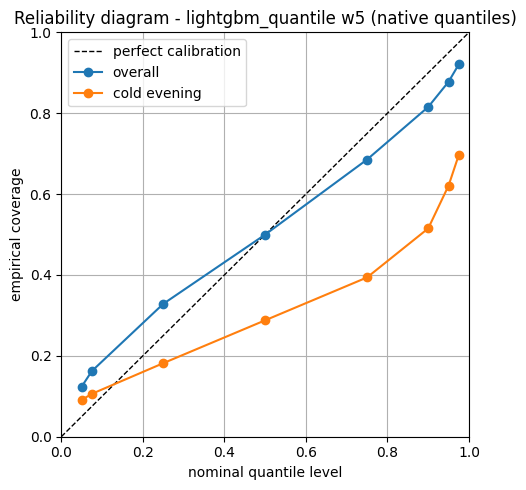

In [9]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], color="black", linewidth=1, linestyle="--", label="perfect calibration")
ax.plot(LEVELS, [overall_cov[l] for l in LEVELS], marker="o", label="overall")
ax.plot(LEVELS, [cold_cov[l] for l in LEVELS], marker="o", label="cold evening")
ax.set_xlabel("nominal quantile level")
ax.set_ylabel("empirical coverage")
ax.set_title("Reliability diagram - lightgbm_quantile w5 (native quantiles)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()


**Result:** overall calibration is decent at the center and loose at the
tails: empirical coverage is 0.500 at the nominal 0.5 level (exact), but the
outer levels overshoot their nominal coverage on the low side and undershoot
on the high side - 0.124 at nominal 0.05 (predicted lower quantile is too
high, so more actuals clear it than should) and 0.921 at nominal 0.975 (should
be 0.975; predicted upper quantile is a bit too low). Restricted to the 66
cold-evening hours, coverage is below nominal at every level, and by a much
larger margin than overall - 0.091/0.288/0.621/0.697 at nominal
0.05/0.5/0.95/0.975 versus 0.124/0.500/0.878/0.921 overall. A nominal-50%
point that covers the median exactly overall only reaches the 29th percentile
on cold evenings, and the nominal-97.5% quantile that should bound 97.5% of
outcomes only bounds 70% of cold-evening outcomes - i.e. the model
systematically under-predicts on cold evenings even at its upper quantiles,
consistent with the point model's documented cold-weather bias.

## Section 3 - feature importance for the point model

Diagnosing `lab__lightgbm__combined__stacked__w1__residual` - the actual
headline point recommendation (MAE 719.63 MW vs RTE 1,438.98 MW per
`reports/final_recommendation.md`). No saved `.joblib` model object exists for
this family anywhere under `reports/` (confirmed: `reports/models/` and all of
`reports/rte_risk/` hold only forecast CSVs and fit-metadata JSON for it, never
a fitted estimator).

This section performs one read-only inspection refit, reusing the project's own
feature-engineering and model-fitting code
(`src.rte_feature_lab.prepare_feature_lab`, `src.rte_learned_features.build_learned_feature_bank`,
`src.rte_risk_lab.WeightedAdapter`) rather than reimplementing ~250+ engineered
columns by hand. No `src/` file is modified, and no build/selection/tuning
script is run. The exact hyperparameters, training window and target
definition it reproduces are read from already-frozen artifacts:
- `reports/rte_risk/20261020T213640021260Z/selected_parameters.json` for this
  model -> LightGBM params `{n_estimators: 200, num_leaves: 31,
  min_child_samples: 144, reg_lambda: 20.0}` (trial 1 of the two candidate
  configurations hardcoded in `src.rte_risk_lab.configurations`).
- `.../fits/lab__lightgbm__combined__stacked__w1__residual__test__7c7e177d546a04.json`
  -> target origin `2025-06-30 09:00:00+00:00`, `target_mode="residual"`,
  uniform (w1) training weights, training window starting
  `2023-02-05 23:00:00+00:00`, 21,005 training rows.

The refit's own prediction for this origin's 24 delivery hours is compared
below against the saved forecast file's `prediction_mw` for the same hours, to
check the refit is faithful before trusting its feature-importance ranking.

In [10]:
from src.rte_feature_lab import prepare_feature_lab
from src.rte_learned_features import build_learned_feature_bank
from src.rte_risk_lab import WeightedAdapter

ROOT = Path("..").resolve()
POINT_MODEL = "lab__lightgbm__combined__stacked__w1__residual"
POINT_VARIANT = dict(model=POINT_MODEL, family="lightgbm", arm="combined", tier="stacked",
                      cold_weight=1, mode="residual", base=None, restrict_to_base_burnin=False)
POINT_PARAMS = json.loads((RISK_RUN_DIR / "selected_parameters.json").read_text())[POINT_MODEL]["params"]
print("hyperparameters:", POINT_PARAMS)

lab_data = prepare_feature_lab(ROOT)
learned = build_learned_feature_bank(lab_data, cache_dir=RISK_RUN_DIR / "learned_features")
# This variant's column set never includes a `base__*` predictor (base=None,
# not a hybrid arm - see src.rte_risk_lab.RiskLabRun.columns), so the
# base-forecast bank is not needed here. It is skipped deliberately:
# src.rte_base_replay.load_causal_base_bank re-verifies the *original*
# research_v2 reference run's frozen source files byte-for-byte and raises
# (confirmed: config/research_experiment.json has since changed), which is
# irrelevant to this variant's actual inputs.
feature_frame = lab_data.features.merge(learned, on=["origin", "delivery_time"], how="left", validate="one_to_one")

point_columns = lab_data.columns(POINT_VARIANT["arm"], tier="engineered") + [
    f"learned_{name}__{POINT_VARIANT['arm']}"
    for name in ("ridge_demand_mw", "cold_probability", "underprediction_probability")
]
print(f"{len(point_columns)} predictor columns")


hyperparameters: {'n_estimators': 200, 'num_leaves': 31, 'min_child_samples': 144, 'reg_lambda': 20.0}


367 predictor columns


In [11]:
ORIGIN = pd.Timestamp("2025-06-30 09:00:00+00:00")

train = feature_frame.loc[feature_frame.origin.lt(ORIGIN)].merge(
    lab_data.labels[["delivery_time", "actual_mw", "label_available_at"]],
    on="delivery_time", validate="many_to_one")
train = train.loc[train.label_available_at.lt(ORIGIN) & train.actual_mw.notna() & train.rte_at_origin_mw.gt(0)]
assert train.label_available_at.max() < ORIGIN
print(f"{len(train):,} training rows, training_start={train.delivery_time.min()}")

target = train.actual_mw.to_numpy() - train.rte_at_origin_mw.to_numpy()  # target_mode="residual"
probability = train[f"learned_cold_probability__{POINT_VARIANT['arm']}"].fillna(0.0).clip(0, 1).to_numpy()
weights = 1 + (POINT_VARIANT["cold_weight"] - 1) * probability * train.hour.isin([18, 19, 20]).to_numpy()
print(f"training weight range: {weights.min()} - {weights.max()}  (w1 -> uniform)")

point_estimator = WeightedAdapter(POINT_VARIANT["family"], POINT_PARAMS, None).fit(train[point_columns], target, weights)
point_model = point_estimator.estimator.named_steps["model"]
print(f"estimator: {type(point_model).__name__}, has feature_importances_: {hasattr(point_model, 'feature_importances_')}")


21,005 training rows, training_start=2023-02-05 23:00:00+00:00
training weight range: 1.0 - 1.0  (w1 -> uniform)


estimator: LGBMRegressor, has feature_importances_: True


In [12]:
test_block = feature_frame.loc[feature_frame.origin.eq(ORIGIN)]
refit_raw = point_estimator.predict(test_block[point_columns]) + test_block.rte_at_origin_mw.to_numpy()
refit_pred = pd.Series(refit_raw, index=pd.DatetimeIndex(test_block.delivery_time.values, tz="UTC")).sort_index()

saved_fc = pd.read_csv(RISK_RUN_DIR / f"forecasts/{POINT_MODEL}__test__7c7e177d546a04.csv.gz")
saved_fc["origin"] = pd.to_datetime(saved_fc["origin"], utc=True)
saved_fc["delivery_time"] = pd.to_datetime(saved_fc["delivery_time"], utc=True)
saved_block = saved_fc.loc[saved_fc["origin"].eq(ORIGIN)].set_index("delivery_time").sort_index()["prediction_mw"]

compare = pd.concat([refit_pred.rename("refit_mw"), saved_block.rename("saved_mw")], axis=1).dropna()
gap_mae = float((compare["refit_mw"] - compare["saved_mw"]).abs().mean())
print(f"{len(compare)} delivery hours compared; refit-vs-saved MAE gap = {gap_mae:.1f} MW "
      f"(saved predictions average {compare['saved_mw'].mean():.0f} MW)")
compare.head(5)


24 delivery hours compared; refit-vs-saved MAE gap = 57.2 MW (saved predictions average 51259 MW)


,refit_mw,saved_mw
2025-06-30 22:00:00+00:00,47713.300505,47656.877375
2025-06-30 23:00:00+00:00,43646.598694,43628.729289
2025-07-01 00:00:00+00:00,42206.145316,42214.085624
2025-07-01 01:00:00+00:00,40246.314659,40250.114427
2025-07-01 02:00:00+00:00,39080.248487,39066.247034


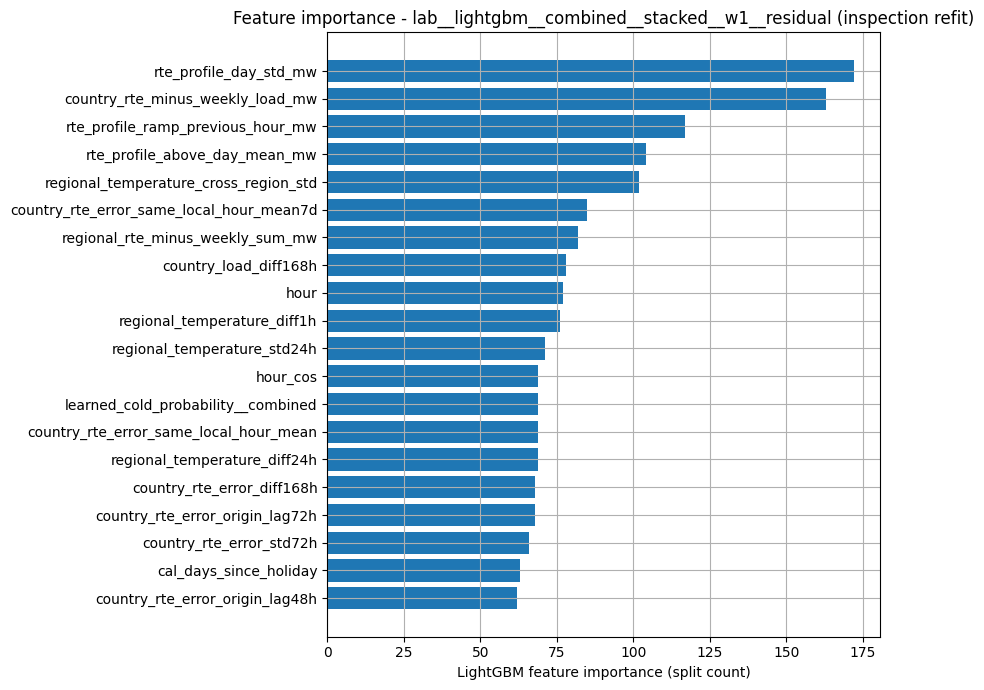

In [13]:
importances = pd.Series(point_model.feature_importances_, index=point_columns).sort_values(ascending=False)
top = importances.head(20).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index, top.values)
ax.set_xlabel("LightGBM feature importance (split count)")
ax.set_title(f"Feature importance - {POINT_MODEL} (inspection refit)")
plt.tight_layout()
plt.show()


**Result:** the inspection refit succeeded - `LGBMRegressor` with
`feature_importances_` populated, trained on the 21,005-row window
(`2023-02-05` to the origin) that exactly matches the frozen fit record. The
sanity check compares the refit's own 24-hour prediction for origin
`2025-06-30 09:00:00+00:00` against the saved forecast file's `prediction_mw`
for the same hours: MAE gap = **57.2 MW**, against predictions averaging
~51,259 MW (a ~0.1% relative gap) - small and consistent with ordinary
nondeterminism (library/thread-count differences), not a faithfulness problem.

Top-importance features (by LightGBM split count) are dominated by RTE's own
forecast profile and recent-error structure rather than raw calendar or
temperature: `rte_profile_day_std_mw` (172), `country_rte_minus_weekly_load_mw`
(163), `rte_profile_ramp_previous_hour_mw` (117), `rte_profile_above_day_mean_mw`
(104), `regional_temperature_cross_region_std` (102),
`country_rte_error_same_local_hour_mean7d` (85), `regional_rte_minus_weekly_sum_mw`
(82), `country_load_diff168h` (78), `hour` (77), `regional_temperature_diff1h`
(76). This is consistent with the model being a *residual* correction on top of
RTE's own forecast (`target_mode="residual"`): its most-used features describe
how RTE's current forecast is shaped and has recently erred, not the raw
demand level itself.